# A simple convolutional autoencoder: improving reconstruction through training

This **worked example** compares three training strategies **without changing the neural network architecture or the latent representation**:

- **A — Baseline:** 120 epochs, waveform mean squared error (MSE).
- **B — Longer training:** 500 epochs, MSE and a learning-rate scheduler.
- **C — Spectral training:** 500 epochs, a scheduler, and a combination of waveform and spectral loss.

All three models start from **identical initial weights** and use the same input waveform. We compare waveform MSE, a log-spectral magnitude difference, and listening results. A lower spectral loss does not necessarily imply better MSE or better perceived sound quality.

## 1. Imports and reproducibility

In [1]:
from pathlib import Path
import numpy as np
import matplotlib.pyplot as plt
import torch
from torch import nn
from torch.nn import functional as F
from scipy.io import wavfile
from scipy.signal import resample_poly
from math import gcd
from IPython.display import Audio, display

np.random.seed(7)
torch.manual_seed(7)
torch.set_num_threads(2)
device = torch.device("cpu")  # CPU is sufficient for this small demonstration


## 2. Load a short sound

The course recording is used if present. Otherwise, the notebook generates a reproducible harmonic sound, so every cell can be run without external files. We use **8 kHz mono audio** and a short segment to keep training fast.

Using course recording: ../sounds/162095-chinese-orchestra-channel-1.wav
Input tensor (batch, channels, samples): (1, 1, 4000)


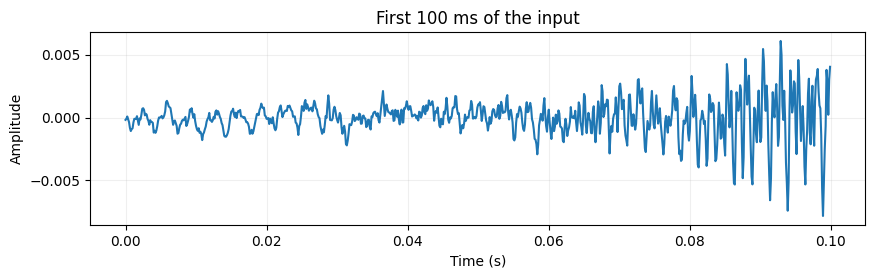

In [2]:
def load_mono_audio(path, target_sr=8000):
    sr, data = wavfile.read(path)
    if np.issubdtype(data.dtype, np.integer):
        info = np.iinfo(data.dtype)
        data = data.astype(np.float32) / max(abs(info.min), info.max)
    else:
        data = data.astype(np.float32)
    if data.ndim == 2:
        data = data.mean(axis=1)  # stereo -> mono
    if sr != target_sr:
        divisor = gcd(sr, target_sr)
        data = resample_poly(data, target_sr // divisor, sr // divisor).astype(np.float32)
    return data, target_sr

fs = 8000
source = Path('../sounds/162095-chinese-orchestra-channel-1.wav')
if source.exists():
    waveform, fs = load_mono_audio(source, fs)
    print('Using course recording:', source)
else:
    t = np.arange(fs) / fs
    waveform = (0.45*np.sin(2*np.pi*220*t) +
                0.23*np.sin(2*np.pi*440*t) +
                0.12*np.sin(2*np.pi*660*t)).astype(np.float32)
    print('Using a generated harmonic sound (course WAV not found).')

# Use exactly 0.5 seconds, which is divisible by the encoder stride.
x = waveform[:fs//2].copy()
if len(x) < fs//2:
    x = np.pad(x, (0, fs//2-len(x)))
assert len(x) == 4000
X = torch.tensor(x, dtype=torch.float32, device=device)[None, None, :]
print('Input tensor (batch, channels, samples):', tuple(X.shape))

display(Audio(x, rate=fs, normalize=False))
plt.figure(figsize=(10, 2.5))
plt.plot(np.arange(800)/fs, x[:800]); plt.xlabel('Time (s)'); plt.ylabel('Amplitude')
plt.title('First 100 ms of the input'); plt.grid(alpha=.2); plt.show()


## 3. Encoder and decoder

The encoder has four learned analysis filters. It uses a kernel of 16 samples and a stride of 8, so the feature sequence is approximately **8 times shorter in time**, but has **4 channels**. In total, the latent tensor contains about half as many scalar values as the input; fewer time steps alone does not mean the representation is smaller.

We choose `kernel_size=16`, `stride=8`, and `padding=4` for both directions. For input lengths divisible by 8, the transposed convolution reconstructs exactly the original length:

$$L_{\mathrm{enc}} = \left\lfloor\frac{L+2p-k}{s}\right\rfloor+1, \qquad L_{\mathrm{dec}}=(L_{\mathrm{enc}}-1)s-2p+k.$$

A transposed convolution is a **learned synthesis operation**, not generally a mathematical inverse of convolution.

In [3]:
class SimpleConvAutoencoder(nn.Module):
    def __init__(self):
        super().__init__()
        self.analysis = nn.Conv1d(1, 4, kernel_size=16, stride=8, padding=4)
        self.synthesis = nn.ConvTranspose1d(4, 1, kernel_size=16, stride=8, padding=4)

    def encode(self, x):
        return F.relu(self.analysis(x))  # nonlinear latent features

    def decode(self, z):
        return self.synthesis(z)  # back to one-channel waveform

    def forward(self, x):
        return self.decode(self.encode(x))

model = SimpleConvAutoencoder().to(device)
with torch.no_grad():
    z = model.encode(X)
    y_initial = model.decode(z)
print('Input:         ', tuple(X.shape))
print('Latent features:', tuple(z.shape))
print('Reconstruction:', tuple(y_initial.shape))
print('Latent elements / input samples:', f'{z.numel()/X.numel():.2f}')
print('Trainable parameters:', sum(p.numel() for p in model.parameters()))
assert y_initial.shape == X.shape


Input:          (1, 1, 4000)
Latent features: (1, 4, 500)
Reconstruction: (1, 1, 4000)
Latent elements / input samples: 0.50
Trainable parameters: 133


## 4. Compare three training strategies

We hold the architecture, the latent size, the waveform, and the initial weights constant. Only the training configuration changes.

The waveform reconstruction objective is

$$
L_{\mathrm{MSE}}=\frac{1}{N}\sum_{n=0}^{N-1}\bigl(x[n]-\hat{x}[n]\bigr)^2.
$$

For version C, we add a **log-magnitude spectral discrepancy**:

$$
L_{\mathrm{spec}}=\frac{1}{B}\sum_{k=0}^{B-1}\left|\log(1+|X[k]|)-\log(1+|\hat{X}[k]|)\right|.
$$

Here $X[k]$ and $\hat{X}[k]$ are the real FFTs of the full 4,000-sample example. The combined training objective is $L=L_{\mathrm{MSE}}+0.01L_{\mathrm{spec}}$. This full-signal spectral loss is simple to demonstrate but is **not** a multiresolution perceptual audio loss. The learning-rate scheduler reduces the learning rate if the training objective plateaus.

In [4]:
import copy

# Clone the same initialization so differences are due to training, not random weights.
initial_weights = copy.deepcopy(model.state_dict())


def spectral_distance(reference, estimate):
    """Mean absolute discrepancy between log(1 + magnitude) spectra."""
    a = torch.abs(torch.fft.rfft(reference, dim=-1))
    b = torch.abs(torch.fft.rfft(estimate, dim=-1))
    return torch.mean(torch.abs(torch.log1p(a) - torch.log1p(b)))


def run_training(label, epochs, use_scheduler=False, use_spectral=False):
    network = SimpleConvAutoencoder().to(device)
    network.load_state_dict(copy.deepcopy(initial_weights))
    optimizer = torch.optim.Adam(network.parameters(), lr=0.001)
    scheduler = (torch.optim.lr_scheduler.ReduceLROnPlateau(
        optimizer, mode='min', factor=0.5, patience=30)
        if use_scheduler else None)
    history = {'objective': [], 'mse': [], 'spectral': [], 'lr': []}
    network.train()
    for epoch in range(epochs):
        optimizer.zero_grad()
        output = network(X)
        mse = F.mse_loss(output, X)
        spectral = spectral_distance(X, output)
        objective = mse + 0.01 * spectral if use_spectral else mse
        objective.backward()
        optimizer.step()
        if scheduler is not None:
            scheduler.step(objective.item())
        history['objective'].append(float(objective.item()))
        history['mse'].append(float(mse.item()))
        history['spectral'].append(float(spectral.item()))
        history['lr'].append(float(optimizer.param_groups[0]['lr']))
    network.eval()
    with torch.no_grad():
        output = network(X)
        mse = float(F.mse_loss(output, X).item())
        spectral = float(spectral_distance(X, output).item())
        signal = output.cpu().numpy()[0, 0].copy()
        latent = network.encode(X)
    return dict(name=label, network=network, history=history,
                mse=mse, spectral=spectral, reconstruction=signal,
                latent_shape=tuple(latent.shape))

# Baseline and alternative strategies share the SAME architecture and latent size.
results = [
    run_training('A: 120 epochs / MSE', 120),
    run_training('B: 500 epochs / MSE + scheduler', 500, use_scheduler=True),
    run_training('C: 500 epochs / combined loss', 500, use_scheduler=True, use_spectral=True),
]

print('Trainable parameters:', sum(p.numel() for p in model.parameters()))
print('Input shape:', tuple(X.shape))
for result in results:
    print(f"{result['name']}: latent {result['latent_shape']}, "
          f"MSE={result['mse']:.6g}, spectral distance={result['spectral']:.6g}")


Trainable parameters: 133
Input shape: (1, 1, 4000)
A: 120 epochs / MSE: latent (1, 4, 500), MSE=0.00768881, spectral distance=0.292322
B: 500 epochs / MSE + scheduler: latent (1, 4, 500), MSE=0.000250674, spectral distance=0.271143
C: 500 epochs / combined loss: latent (1, 4, 500), MSE=0.000293796, spectral distance=0.264009


## 5. Compare errors and convergence

MSE and spectral discrepancy measure **different properties**. Version B may improve the waveform fit through longer training; version C explicitly optimizes spectral magnitude and may trade waveform accuracy for spectral accuracy. Results depend on the waveform, optimizer, and initialization.

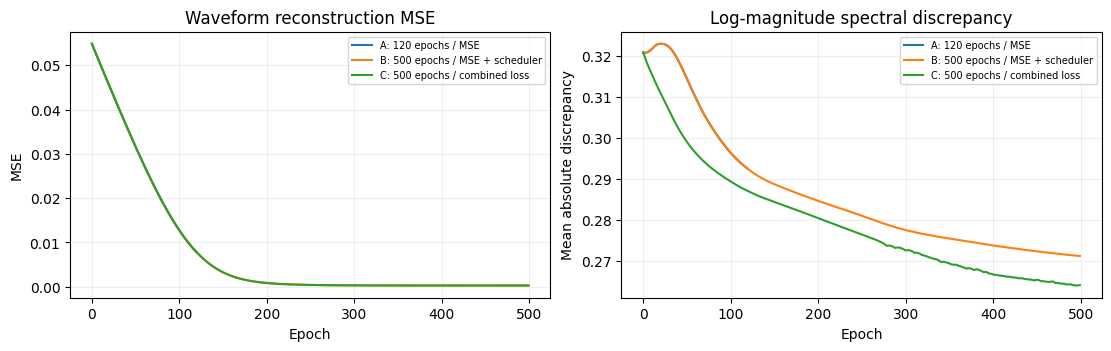

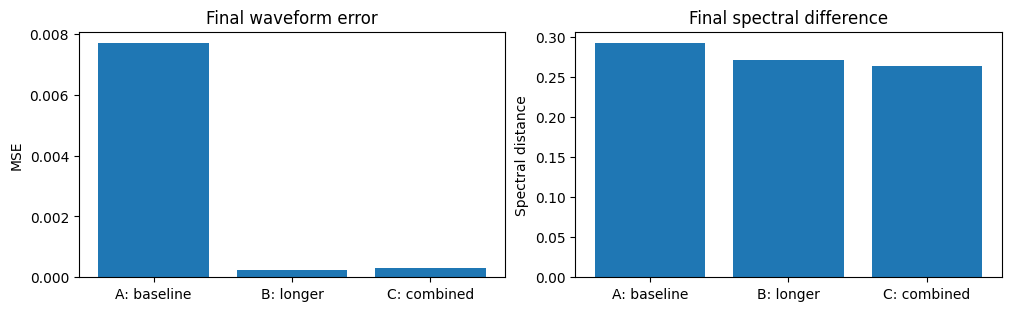

In [5]:
fig, ax = plt.subplots(1, 2, figsize=(11, 3.4), constrained_layout=True)
for result in results:
    h = result['history']
    ax[0].plot(h['mse'], label=result['name'])
    ax[1].plot(h['spectral'], label=result['name'])
ax[0].set(title='Waveform reconstruction MSE', xlabel='Epoch', ylabel='MSE')
ax[1].set(title='Log-magnitude spectral discrepancy', xlabel='Epoch', ylabel='Mean absolute discrepancy')
for a in ax:
    a.grid(alpha=0.2)
    a.legend(fontsize=7)
plt.show()

labels = ['A: baseline', 'B: longer', 'C: combined']
fig, ax = plt.subplots(1, 2, figsize=(10, 3), constrained_layout=True)
ax[0].bar(labels, [r['mse'] for r in results]); ax[0].set(ylabel='MSE', title='Final waveform error')
ax[1].bar(labels, [r['spectral'] for r in results]); ax[1].set(ylabel='Spectral distance', title='Final spectral difference')
plt.show()


## 6. Waveform and audio comparison

The original and three reconstructions are all played using **one common gain**. This prevents automatic, independent normalization from hiding loudness differences. The example trains on this one short sound; these results do **not** measure generalization to unseen audio.

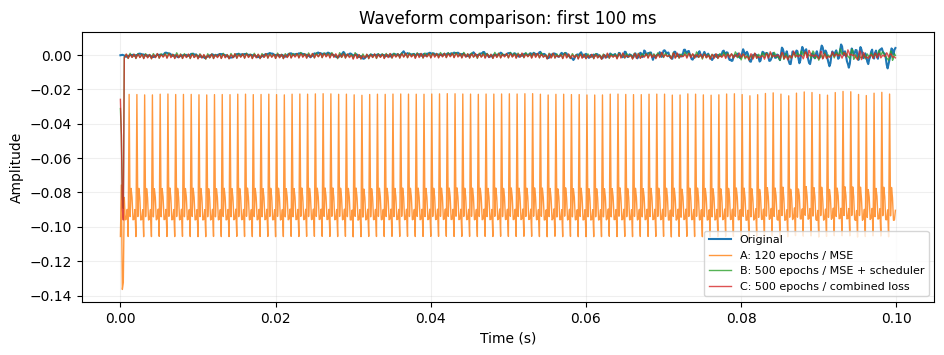

Original audio:


A: 120 epochs / MSE


B: 500 epochs / MSE + scheduler


C: 500 epochs / combined loss


In [6]:
t_view = np.arange(800) / fs
plt.figure(figsize=(11, 3.5))
plt.plot(t_view, x[:800], label='Original', lw=1.5)
for r in results:
    plt.plot(t_view, r['reconstruction'][:800], lw=1, alpha=0.8, label=r['name'])
plt.xlabel('Time (s)'); plt.ylabel('Amplitude'); plt.title('Waveform comparison: first 100 ms')
plt.legend(fontsize=8); plt.grid(alpha=0.2); plt.show()

# Common playback gain prevents clipping while maintaining relative loudness.
all_peaks = [np.max(np.abs(x))] + [np.max(np.abs(r['reconstruction'])) for r in results]
gain = 0.9 / max(max(all_peaks), 1e-9)
print('Original audio:')
display(Audio(x * gain, rate=fs, normalize=False))
for result in results:
    print(result['name'])
    display(Audio(result['reconstruction'] * gain, rate=fs, normalize=False))


## 7. Latent size and learned filters

All three networks use **exactly the same** `(batch, channels, time positions)` latent shape and number of parameters. Improving training does not increase the latent count. The filters may learn different weights, but there are still four analysis filters and four synthesis kernels.

A: 120 epochs / MSE: 2000 latent float32 values, 8000 bytes vs 16000 input bytes (2.00x fewer bytes)
B: 500 epochs / MSE + scheduler: 2000 latent float32 values, 8000 bytes vs 16000 input bytes (2.00x fewer bytes)
C: 500 epochs / combined loss: 2000 latent float32 values, 8000 bytes vs 16000 input bytes (2.00x fewer bytes)


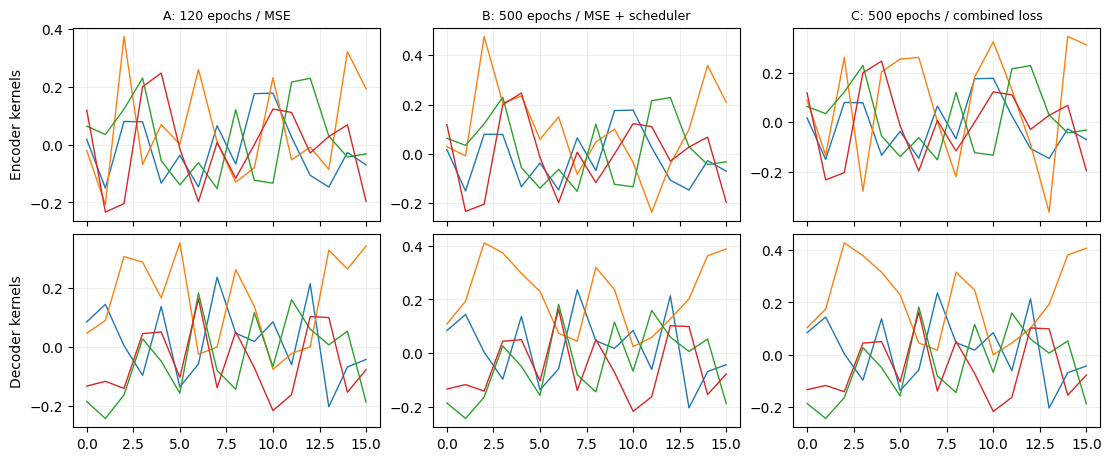

In [7]:
for r in results:
    z = r['network'].encode(X)
    input_bytes = X.numel() * X.element_size()
    latent_bytes = z.numel() * z.element_size()
    print(f"{r['name']}: {z.numel()} latent float32 values, "
          f"{latent_bytes} bytes vs {input_bytes} input bytes "
          f"({input_bytes / latent_bytes:.2f}x fewer bytes)")

fig, axes = plt.subplots(2, 3, figsize=(11, 4.5), sharex=True, constrained_layout=True)
for j, r in enumerate(results):
    net = r['network']
    for i in range(4):
        axes[0, j].plot(net.analysis.weight.detach().cpu().numpy()[i, 0], lw=1)
        axes[1, j].plot(net.synthesis.weight.detach().cpu().numpy()[i, 0], lw=1)
    axes[0, j].set_title(r['name'], fontsize=9)
    axes[0, j].grid(alpha=0.2); axes[1, j].grid(alpha=0.2)
axes[0, 0].set_ylabel('Encoder kernels'); axes[1, 0].set_ylabel('Decoder kernels')
plt.show()


## What to remember

- Reconstruction can improve through **training choices**, with no change in network size or latent tensor dimensions.
- More epochs can improve convergence, but they do not guarantee a better result.
- A learning-rate scheduler may help the optimizer settle into a better solution.
- A spectral loss emphasizes spectral magnitude; **waveform accuracy and perceived audio quality are different objectives**.
- Here the network learns to reconstruct **one short training signal**. Testing on unseen recordings is needed to evaluate generalization.
- A smaller floating-point latent tensor is **not yet** a complete compressed audio format: it lacks quantization, entropy coding, and decoder storage considerations.